# **VAE**

## **Objetivo del notebook**

Este notebook implementa un autoencoder variacional (VAE) convolucional para reconstruir rostros de `64x64` píxeles en escala de grises y generar imágenes nuevas desde un espacio latente probabilístico.

El flujo es: cargar y validar el dataset, normalizar y separar los datos, construir encoder y decoder, muestrear el latente con reparametrización, entrenar con reconstrucción más divergencia KL, visualizar resultados, generar la submission y evaluar el muestreo con FID.

### **Diferencia respecto a `AE`**

En el AE, el encoder transforma cada imagen en un único vector determinista `z` y el decoder optimiza principalmente su reconstrucción. Ese latente puede ser irregular, por lo que muestrear `z ~ N(0, I)` no está garantizado.

En este VAE, el encoder devuelve `z_mean` y `z_log_var`, los parámetros de una distribución normal por imagen. Se obtiene una muestra `z` mediante una reparametrización. Así el espacio latente se regulariza para que muestrear desde `N(0,I)` sea coherente con el entrenamiento.

La contrapartida es que parte de la capacidad se dedica a organizar el latente; por eso las reconstrucciones tienden a ser más borrosas que en un AE entrenado para reconstruir.

---

### **Dependencias y entorno**

Se instalan las librerías de visión, cálculo numérico, visualización y aprendizaje profundo. TensorFlow/Keras construye y entrena el VAE; PyTorch y `torchmetrics` se utilizan más adelante para calcular FID.

In [ ]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install torch

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from google.colab import drive

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
# Si se trabaja en Google Colab:

drive.mount('/content/drive')

# Si el dataset está en la carpeta 'Metodos-generativos', la ruta será:
DATASET_DIR = "/content/drive/MyDrive/Metodos-Generativos/data/images"

# Ruta de los archivos ZIP en Google Drive
zip_path = "/content/drive/MyDrive/Metodos-Generativos/data.zip"

# Destino local donde se descomprimirá el ZIP
dest_dir = "/content"

if os.path.exists(zip_path):
    os.makedirs(dest_dir, exist_ok=True)
    print(f"Descomprimiendo {zip_path} en {dest_dir}...")
    !unzip -q "{zip_path}" -d "{dest_dir}"
    print("Descompresión completada")
else:
    print(f"Error: No se encontró el ZIP en la ruta: {zip_path}")

Mounted at /content/drive
Descomprimiendo /content/drive/MyDrive/Metodos-Generativos/data.zip en /content...
¡Descompresión completada con éxito!


---

## **Carga de datos y split**

Se cargan las `30.000` imágenes en escala de grises (la submission usa un solo canal), se verifican forma, tipo y rango, y se visualiza una muestra. Después se fija la semilla y se separa el `90%` para entrenamiento y el `10%` para validación. La validación no se usa para actualizar pesos ni para generar la submission: solo sirve para el criterio de parada y como referencia real del FID.

In [4]:
DATASET_DIR = "data/images"
IMG_SIZE = 64
TOTAL_IMAGES = 30000

images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [ ]:
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {filepath}")
    
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [ ]:
# Comprobaciones numéricas 
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


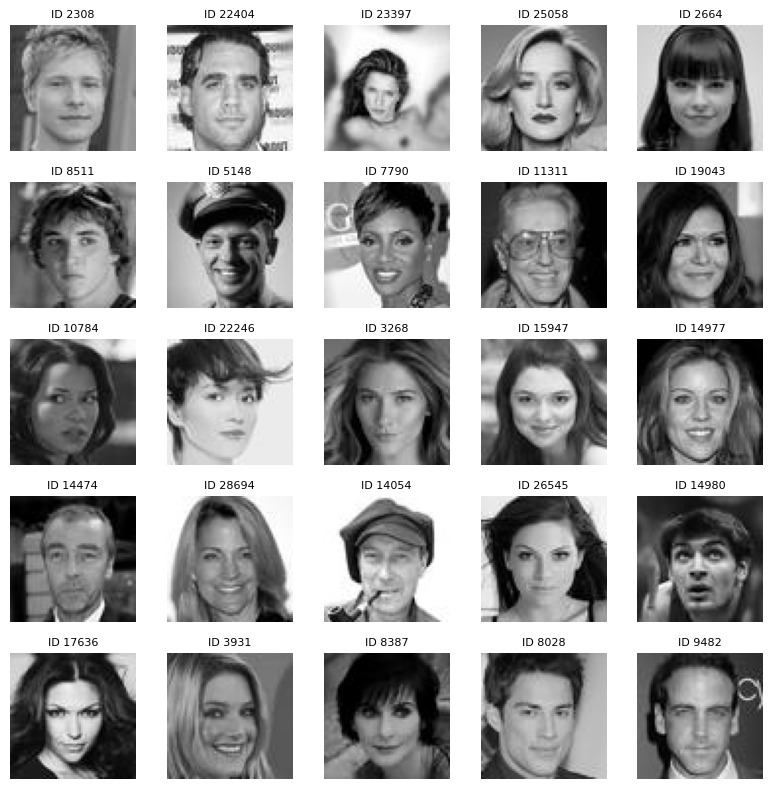

In [7]:
# Visualización de una cuadrícula de 5x5 imágenes
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

---

## **Implementación del VAE**

Esta sección contiene la parte que diferencia al VAE del `AE`: el encoder produce una distribución latente y el modelo completo aprende mediante una pérdida ELBO. La convolución, la reducción espacial y la reconstrucción mantienen la misma idea general del AE, de modo que la comparación se centra en la representación y el objetivo de entrenamiento.

In [9]:
# Semillas para reproducibilidad
SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

### **Normalización y split**

Los píxeles pasan de `[0,255]` a `[0,1]`, rango compatible con la salida `sigmoid` del decoder y con la BCE. Se añade el eje de canal para obtener `(N,64,64,1)`. El `90%` se usa para actualizar pesos y el `10%` queda reservado para validación.

In [10]:
# Preprocesamiento y split (90% Train / 10% Val)

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

val_size = int(0.10 * len(x_data))
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


### **Reparametrización**

El encoder debe aprender `z_mean` y `z_log_var`, pero una muestra aleatoria directa bloquearía el cálculo de gradientes. Se aplica la reparametrización escribiendo `z = z_mean + sigma * epsilon`, donde `epsilon ~ N(0,I)` y `sigma = exp(0.5 * z_log_var)`.

In [ ]:
# Reparametrización: z = mu + sigma * epsilon
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

### **Encoder**

Las cuatro convoluciones reducen `64 -> 32 -> 16 -> 8 -> 4` y aumentan los canales `32 -> 64 -> 128 -> 256`. Tras aplanar `4x4x256`, dos capas densas predicen, por separado, la media y el logaritmo de la varianza de una normal de `128` dimensiones. El tercer resultado, `z`, es la muestra que se entrega al decoder durante el entrenamiento.

In [ ]:
# Arquitectura del VAE 
LATENT_DIM = 128

# Encoder
encoder_inputs = keras.Input(shape=(64, 64, 1), name="encoder_input")
x = layers.Conv2D(32, kernel_size=4, strides=2, padding="same")(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Flatten()(x)
z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        544 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 32, 32,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 16,    │     32,832 │ leaky_re_lu[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 8, 128) │    131,200 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 4, 4, 256) │    524,544 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 256) │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 4, 4, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 128)       │    524,416 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 128)       │    524,416 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 128)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,739,872 (6.64 MB)

 Trainable params: 1,738,912 (6.63 MB)

 Non-trainable params: 960 (3.75 KB)

### **Decoder**

El decoder invierte la compresión: una capa densa reconstruye un mapa `4x4x256` y cuatro `Conv2DTranspose` duplican sucesivamente la resolución hasta `64x64`. La convolución final con `sigmoid` devuelve un canal con valores en `[0,1]`. Arquitectónicamente se parece al decoder del AE; la diferencia está en que recibe muestras de una distribución latente regularizada.

In [13]:
# Decoder
latent_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

x = layers.Dense(4 * 4 * 256)(latent_inputs)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

x = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(32, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2DTranspose(16, kernel_size=4, strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

decoder_outputs = layers.Conv2D(1, kernel_size=4, strides=1, padding="same", activation="sigmoid")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │       528,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 16)     │         8,208 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 1)      │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,226,161 (4.68 MB)

 Trainable params: 1,225,681 (4.68 MB)

 Non-trainable params: 480 (1.88 KB)

### **Modelo VAE**

La clase `VAE` une el `encoder` y el `decoder`. El encoder transforma cada imagen en `z_mean` y `z_log_var`, que describen una distribución latente; después obtiene una muestra `z` mediante reparametrización. El decoder usa esa muestra para reconstruir la imagen.

En `_compute_losses`, primero se codifica el batch y se genera la reconstrucción. La pérdida de reconstrucción usa BCE entre los píxeles reales y predichos. La salida se limita a `(1e-7, 1-1e-7)` para evitar `log(0)`, se suman los errores de cada imagen y se calcula la media del batch.

Después se calcula la divergencia KL entre la distribución latente aprendida y la prior `N(0,I)`. Este término fuerza las medias hacia cero y las varianzas hacia uno, haciendo que el muestreo posterior desde `N(0,I)` sea útil para generar imágenes.

La función objetivo combina ambos términos:

`total_loss = rec_loss + beta * kl_loss`, con `beta=0.1` para priorizar la nitidez de las imágenes generadas.

`train_step` calcula esta pérdida, obtiene los gradientes con `GradientTape`, actualiza los pesos y registra `loss`, `rec_loss` y `kl_loss`. `test_step` calcula las mismas métricas sobre validación, pero no actualiza los pesos. Los trackers permiten observar por separado la calidad de reconstrucción y la regularización del espacio latente.

In [14]:
# Modelo VAE completo
class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=0.1, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta  # Factor de ponderación para la pérdida KL
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="rec_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def _compute_losses(self, data):
        # Desempaquetar
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, z = self.encoder(data)
        reconstruction = self.decoder(z)

        # Pérdida de reconstrucción 
        eps = 1e-7
        rec_clipped = tf.clip_by_value(reconstruction, eps, 1.0 - eps)
        bce = -(data * tf.math.log(rec_clipped) + (1.0 - data) * tf.math.log(1.0 - rec_clipped))
        rec_loss_per_sample = tf.reduce_sum(bce, axis=[1, 2, 3])
        rec_loss = tf.reduce_mean(rec_loss_per_sample)

        kl_loss_per_sample = -0.5 * tf.reduce_sum(
            1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), 
            axis=1
        )
        kl_loss = tf.reduce_mean(kl_loss_per_sample)

        total_loss = rec_loss + (self.beta * kl_loss)
        return total_loss, rec_loss, kl_loss

    def train_step(self, data):
        with tf.GradientTape() as tape:
            total_loss, rec_loss, kl_loss = self._compute_losses(data)
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "rec_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        total_loss, rec_loss, kl_loss = self._compute_losses(data)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(rec_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "rec_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

### **Compilación y entrenamiento**

Adam optimiza la pérdida total con tasa `1e-4`. `EarlyStopping` vigila `val_loss` y restaura los mejores pesos, evitando conservar una época posterior que haya empeorado.

In [15]:
# Compilacion y entrenamiento 
vae = VAE(encoder, decoder, beta=0.1)  # Puedes ajustar el valor de beta según tus necesidades
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4))

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 100
BATCH_SIZE = 128

history = vae.fit(
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, x_val),
    callbacks=callbacks,
    shuffle=True
)

---

## **Resultados del entrenamiento y reconstrucciones**

Las siguientes celdas muestran el comportamiento de las reconstrucciones, un resumen de la mejor época según `val_loss` y la evolución de la pérdida.

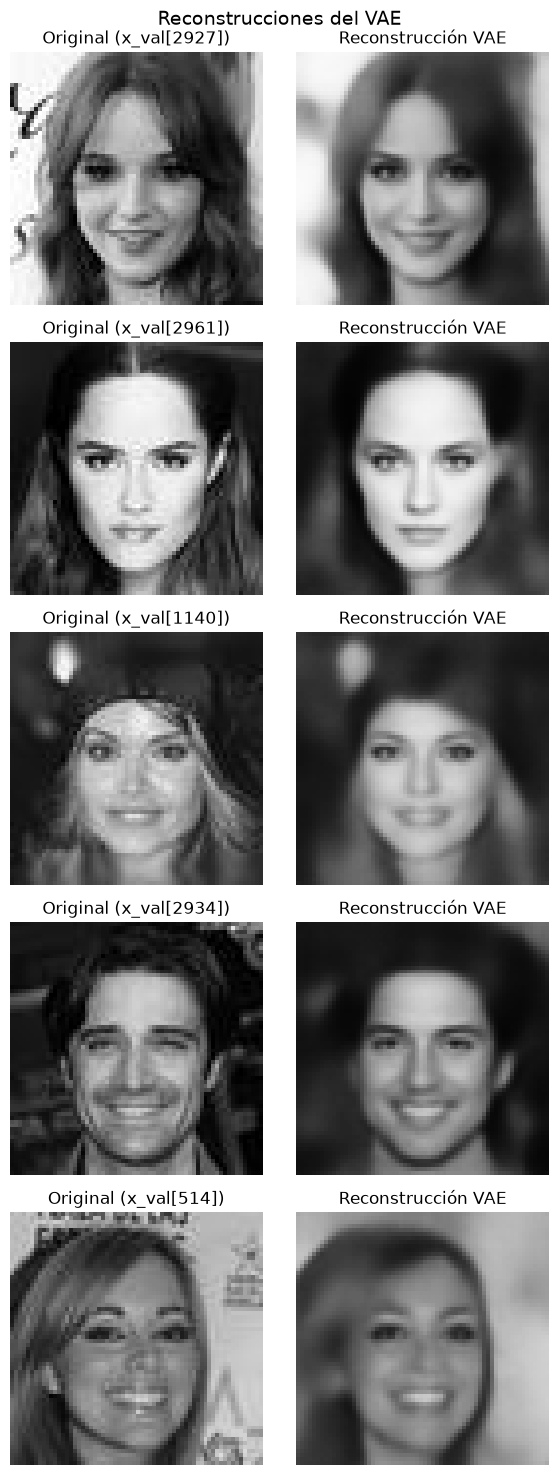

In [ ]:
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)
comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

z_mean_val, _, _ = encoder.predict(x_val_samples, verbose=0)
vae_reconstructions = decoder.predict(z_mean_val, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del VAE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, vae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción VAE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [26]:
# Mejores métricas obtenidas durante el entrenamiento
metrics_history = history.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")
print(f"Train rec_loss:  {metrics_history['rec_loss'][best_epoch]:.4f}")
print(f"Val rec_loss:    {metrics_history['val_rec_loss'][best_epoch]:.4f}")
print(f"Train kl_loss:   {metrics_history['kl_loss'][best_epoch]:.4f}")
print(f"Val kl_loss:     {metrics_history['val_kl_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 60
Train loss:      2176.0596
Validation loss: 2177.1179
Train rec_loss:  2158.7229
Val rec_loss:    2159.8601
Train kl_loss:   173.3676
Val kl_loss:     172.5823


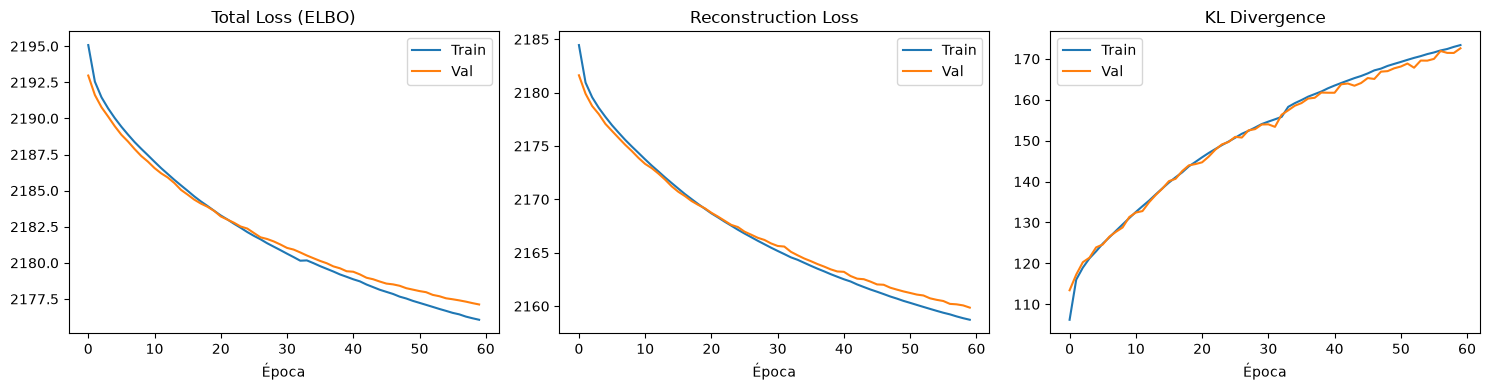

In [27]:
# Plot del entrenamiento
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Val")
axes[0].set_title("Total Loss (ELBO)")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history.history["rec_loss"], label="Train")
axes[1].plot(history.history["val_rec_loss"], label="Val")
axes[1].set_title("Reconstruction Loss")
axes[1].set_xlabel("Época")
axes[1].legend()

axes[2].plot(history.history["kl_loss"], label="Train")
axes[2].plot(history.history["val_kl_loss"], label="Val")
axes[2].set_title("KL Divergence")
axes[2].set_xlabel("Época")
axes[2].legend()

plt.tight_layout()
plt.show()

---

## **Creación de una submission**

In [31]:
# Muestreo de 200 vectores latentes para generar imágenes
N_SAMPLES = 200
LATENT_DIM = 128
SAMPLE_SEED = 1234

np.random.seed(SAMPLE_SEED)
z_samples = np.random.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

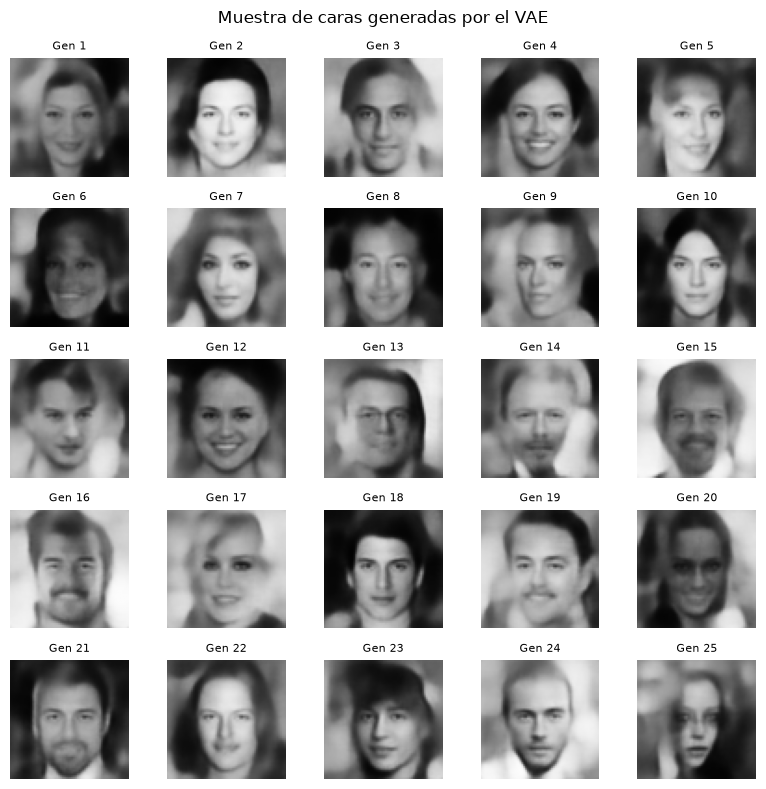

In [32]:
# Decodificación y conversión a uint8 [0, 255]
generated_imgs = vae.decoder.predict(
    z_samples,
    batch_size=N_SAMPLES,
    verbose=0
)

generated_imgs = np.clip(
    np.round(generated_imgs * 255.0), 0, 255
).astype(np.uint8)

generated_imgs = np.squeeze(generated_imgs, axis=-1)

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el VAE", fontsize=12)

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)

plt.tight_layout()
plt.show()

In [27]:
# Generación de la submission del VAE
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)

df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)

df_submission.insert(0, "Usage", "Public")
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

csv_filename = "submission_vae.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}'")

print(f"Forma esperada:  ({N_SAMPLES}, {IMG_SIZE * IMG_SIZE + 2})")
print(f"Forma obtenida:  {df_submission.shape}")
print(f"Rango de IDs:    {df_submission['ID'].min()} a {df_submission['ID'].max()}")
print(f"Valores únicos en 'Usage': {df_submission['Usage'].unique()}")
print(f"Primeras 5 columnas de cabecera: {list(df_submission.columns[:5])}")
print(f"Últimas 3 columnas de cabecera:  {list(df_submission.columns[-3:])}")
print(f"Valores nulos en el dataframe:   {df_submission.isnull().sum().sum()}")

Archivo guardado como 'submission_vae.csv'
Forma esperada:  (200, 4098)
Forma obtenida:  (200, 4098)
Rango de IDs:    1 a 200
Valores únicos en 'Usage': <StringArray>
['Public']
Length: 1, dtype: str
Primeras 5 columnas de cabecera: ['ID', 'Usage', '0', '1', '2']
Últimas 3 columnas de cabecera:  ['4093', '4094', '4095']
Valores nulos en el dataframe:   0


---

## **Evaluación FID del VAE**

In [18]:
%pip install "torchmetrics[image]"

Note: you may need to restart the kernel to use updated packages.


In [19]:
import torch

print("PyTorch:", torch.__version__)
print("MPS disponible:", torch.backends.mps.is_available())
print("Dispositivo FID:", torch.device)

PyTorch: 2.14.1+cpu
MPS disponible: False
Dispositivo FID: <class 'torch.device'>


In [ ]:
from torchmetrics.image.fid import FrechetInceptionDistance

FID_SEED = SEED
FID_BATCH_SIZE = 64
FID_NUM_IMAGES = min(len(x_val), 512)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"


def prepare_images_for_fid(images):
    images = np.asarray(images)
    images = np.clip(images, 0.0, 1.0)
    images = (images * 255.0).round().astype(np.uint8)
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    fid = FrechetInceptionDistance(
        feature=2048,
        normalize=False
    ).to(device)

    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(
                real_images[start:start + batch_size].to(device),
                real=True
            )

        for start in range(0, len(generated_images), batch_size):
            fid.update(
                generated_images[start:start + batch_size].to(device),
                real=False
            )

        return fid.compute().item()


real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_vae_fid = fid_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_vae_fid = decoder.predict(
    z_vae_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

In [29]:
fid_vae = calculate_fid(
    generated_vae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID VAE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_vae:.4f}")

FID VAE (512 imágenes, dispositivo=cpu): 98.2582
